# Smart MCQ Solver

This notebook uses three representative approaches for five-choice MCQs.

1. **Word2Vec + Cosine Similarity** — learned embeddings trained on project text.
2. **Simple CNN** — a from-scratch Embedding → Conv1D → ReLU → max pooling model.
3. **DeBERTa-v3-base** — the final pretrained Kaggle model.


## 1. Project Overview
 The task is evaluated with MAP@3, so the top three ranked answers are predicted


## 2. Imports and Setup



In [46]:
import os
import re
import string

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wandb
from datasets import Dataset
from gensim.models import Word2Vec
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from transformers import (
    AutoModelForMultipleChoice,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    set_seed,
)

OPTION_LABELS = ["A", "B", "C", "D", "E"]
RANDOM_SEED = 42
set_seed(RANDOM_SEED)


## 3. Dataset Loading


In [22]:
data_folder = "/kaggle/input/competitions/smart-mcq-solver-challenge"
train_path = os.path.join(data_folder, "train.csv")
test_path = os.path.join(data_folder, "test.csv")
sample_submission_path = os.path.join(data_folder, "sample_submission.csv")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_submission_df = pd.read_csv(sample_submission_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Columns:", train_df.columns.tolist())
display(train_df.head())


Train shape: (2000, 8)
Test shape: (500, 7)
Columns: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


## 4. Exploratory Data Analysis


Missing values:


id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

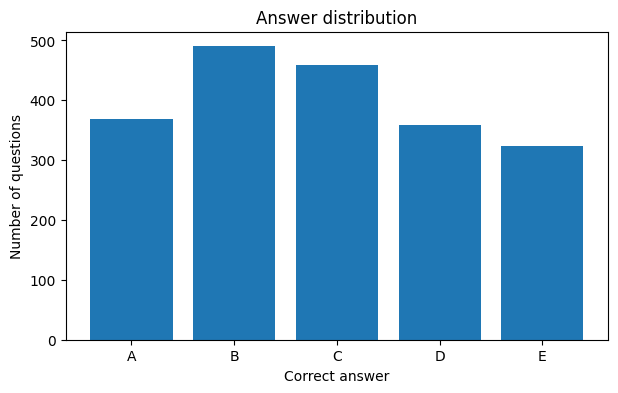

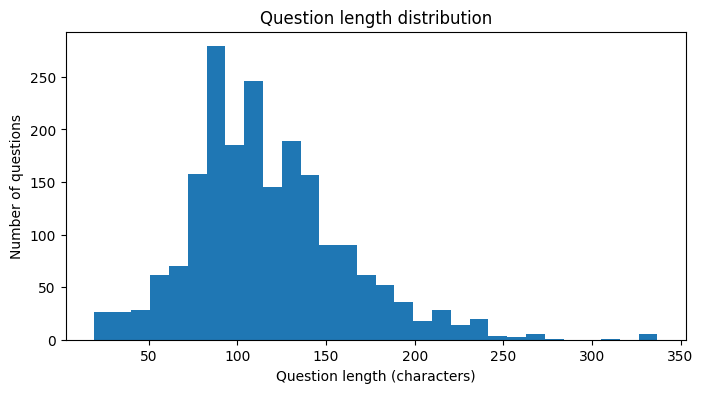

In [23]:
text_columns = ["prompt", *OPTION_LABELS]

print("Missing values:")
display(train_df.isnull().sum())

answer_counts = train_df["answer"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(answer_counts.index, answer_counts.values)
plt.xlabel("Correct answer")
plt.ylabel("Number of questions")
plt.title("Answer distribution")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(train_df["prompt"].fillna("").str.len(), bins=30)
plt.xlabel("Question length (characters)")
plt.ylabel("Number of questions")
plt.title("Question length distribution")
plt.show()


## 5. Basic Preprocessing




In [24]:
for frame in [train_df, test_df]:
    for column in text_columns:
        frame[column] = frame[column].fillna("").astype(str)


def clean_text(text):
    text = text.lower()
    for punctuation_mark in string.punctuation:
        text = text.replace(punctuation_mark, " ")
    return re.sub(r"\s+", " ", text).strip()


for column in text_columns:
    train_df[column + "_clean"] = train_df[column].apply(clean_text)
    test_df[column + "_clean"] = test_df[column].apply(clean_text)

clean_columns = ["prompt_clean", "A_clean", "B_clean", "C_clean", "D_clean", "E_clean"]

label_to_id = {label: index for index, label in enumerate(OPTION_LABELS)}
train_df["label"] = train_df["answer"].map(label_to_id)
display(train_df[["prompt", "prompt_clean", "answer", "label"]].head())


,prompt,prompt_clean,answer,label
0,Pick the best possible answer: What is Martin ...,pick the best possible answer what is martin h...,B,1
1,What is accelerator-based light-ion fusion?,what is accelerator based light ion fusion,A,0
2,Determine the correct option: What is the term...,determine the correct option what is the term ...,C,2
3,Select the most accurate option: What is Marti...,select the most accurate option what is martin...,B,1
4,Identify the correct statement: What is the co...,identify the correct statement what is the con...,A,0


## 6. Evaluation Metric — MAP@3



In [25]:
def average_precision_at_3(actual_answer, predicted_answers):
    top_three = predicted_answers[:3]
    if actual_answer not in top_three:
        return 0.0
    rank = top_three.index(actual_answer) + 1
    return 1.0 / rank


def map_at_3(actual_answers, predictions):
    scores = []
    for actual_answer, predicted_answers in zip(actual_answers, predictions):
        scores.append(average_precision_at_3(actual_answer, predicted_answers))
    return float(np.mean(scores))


## 7. Model 1 — Word2Vec + Cosine Similarity

### 7.1 Idea

**What does this do?** It trains Word2Vec embeddings on the project text and uses them to represent questions and options.

**Why?** This is a learned semantic representation without using a pretrained transformer.


### 7.2 Train Word2Vec

In [26]:
sentences = []
for column in clean_columns:
    for text in train_df[column]:
        sentences.append(text.split())

word2vec = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    seed=RANDOM_SEED,
)
print("Word2Vec vocabulary size:", len(word2vec.wv))


Word2Vec vocabulary size: 3003


### 7.3 Create question/option embeddings

In [27]:
def get_sentence_vector(text):
    word_vectors = []
    for word in text.split():
        if word in word2vec.wv:
            word_vectors.append(word2vec.wv[word])

    if len(word_vectors) == 0:
        return np.zeros(word2vec.vector_size)
    return np.mean(word_vectors, axis=0)


### 7.4 Cosine similarity and Rank top-3

In [28]:
word2vec_predictions = []

for _, row in train_df.iterrows():
    prompt_vector = get_sentence_vector(row["prompt_clean"]).reshape(1, -1)
    option_vectors = []
    for label in OPTION_LABELS:
        option_vectors.append(get_sentence_vector(row[label + "_clean"]))

    scores = cosine_similarity(prompt_vector, np.array(option_vectors))[0]
    ranked_indices = np.argsort(-scores)
    word2vec_predictions.append([OPTION_LABELS[index] for index in ranked_indices])


### 7.6 Evaluation

In [29]:
word2vec_top1 = [prediction[0] for prediction in word2vec_predictions]
word2vec_accuracy = accuracy_score(train_df["answer"], word2vec_top1)
word2vec_macro_f1 = f1_score(train_df["answer"], word2vec_top1, average="macro", zero_division=0)
word2vec_map3 = map_at_3(train_df["answer"].tolist(), word2vec_predictions)

print("Accuracy:", round(word2vec_accuracy, 4))
print("Macro F1:", round(word2vec_macro_f1, 4))
print("MAP@3:", round(word2vec_map3, 4))
# The earlier verified run reported Word2Vec MAP@3 = 0.3327.


Accuracy: 0.1615
Macro F1: 0.1587
MAP@3: 0.3305


### 7.7 Short observation

Word2Vec learns from this project’s text, but averaging word vectors loses word order and detailed context.


## 8. Model 2 — Simple CNN for Multiple Choice

Question + Option A/B/C/D/E → word IDs → Embedding → Conv1D → ReLU → max pooling → linear score → 5 option scores

In [47]:
CNN_CFG = {
    "max_vocab_size": 10000,
    "max_length": 128,
    "embedding_dim": 32,
    "num_filters": 32,
    "kernel_size": 3,
    "batch_size": 64,
    "epochs": 4,
    "learning_rate": 1e-3,
    "validation_size": 0.12,
    "seed": RANDOM_SEED,
}


def build_vocabulary(frame):
    vocabulary = {"<PAD>": 0, "<UNK>": 1}

    for _, row in frame.iterrows():
        for label in OPTION_LABELS:
            text = clean_text(row["prompt"] + " " + row[label])

            for word in text.split():
                if word not in vocabulary and len(vocabulary) < CNN_CFG["max_vocab_size"]:
                    vocabulary[word] = len(vocabulary)

    return vocabulary


def encode_text(text, vocabulary):
    token_ids = []

    for word in clean_text(text).split()[:CNN_CFG["max_length"]]:
        token_ids.append(vocabulary.get(word, vocabulary["<UNK>"]))

    while len(token_ids) < CNN_CFG["max_length"]:
        token_ids.append(vocabulary["<PAD>"])

    return token_ids

### 8.2 Train/validation split and CNN tensors

In [48]:
cnn_frame = train_df[["prompt", *OPTION_LABELS, "label"]].copy()

cnn_train_frame, cnn_valid_frame = train_test_split(
    cnn_frame,
    test_size=CNN_CFG["validation_size"],
    random_state=CNN_CFG["seed"],
    stratify=cnn_frame["label"],
)

vocabulary = build_vocabulary(cnn_train_frame)


def make_cnn_tensors(frame):
    sequences = []
    labels = []

    for _, row in frame.iterrows():
        option_sequences = []

        for label in OPTION_LABELS:
            text = row["prompt"] + " " + row[label]
            option_sequences.append(encode_text(text, vocabulary))

        sequences.append(option_sequences)
        labels.append(int(row["label"]))

    x = torch.tensor(sequences, dtype=torch.long)
    y = torch.tensor(labels, dtype=torch.long)

    return x, y


cnn_train_x, cnn_train_y = make_cnn_tensors(cnn_train_frame)
cnn_valid_x, cnn_valid_y = make_cnn_tensors(cnn_valid_frame)

cnn_train_loader = DataLoader(
    TensorDataset(cnn_train_x, cnn_train_y),
    batch_size=CNN_CFG["batch_size"],
    shuffle=True,
)

cnn_valid_loader = DataLoader(
    TensorDataset(cnn_valid_x, cnn_valid_y),
    batch_size=CNN_CFG["batch_size"],
    shuffle=False,
)

print("Train shape:", cnn_train_x.shape)
print("Validation shape:", cnn_valid_x.shape)

Train shape: torch.Size([1760, 5, 128])
Validation shape: torch.Size([240, 5, 128])


In [49]:
class SimpleCNN(nn.Module):
    def __init__(self, vocabulary_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocabulary_size,
            CNN_CFG["embedding_dim"],
            padding_idx=0,
        )

        self.convolution = nn.Conv1d(
            CNN_CFG["embedding_dim"],
            CNN_CFG["num_filters"],
            kernel_size=CNN_CFG["kernel_size"],
        )

        self.output = nn.Linear(CNN_CFG["num_filters"], 1)

    def forward(self, input_ids):
        batch_size, number_of_options, sequence_length = input_ids.shape

        input_ids = input_ids.view(batch_size * number_of_options, sequence_length)

        embedded = self.embedding(input_ids).transpose(1, 2)
        features = torch.relu(self.convolution(embedded))
        pooled = torch.max(features, dim=2).values

        scores = self.output(pooled).squeeze(1)

        return scores.view(batch_size, number_of_options)


cnn_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cnn_model = SimpleCNN(len(vocabulary)).to(cnn_device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=CNN_CFG["learning_rate"],
)


def evaluate_cnn():
    cnn_model.eval()

    total_loss = 0.0
    all_logits = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in cnn_valid_loader:
            inputs = inputs.to(cnn_device)
            labels = labels.to(cnn_device)

            logits = cnn_model(inputs)
            loss = loss_function(logits, labels)

            total_loss += loss.item() * len(labels)
            all_logits.append(logits.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    logits = np.concatenate(all_logits)
    labels = np.concatenate(all_labels)

    top1_ids = np.argmax(logits, axis=1)
    ranked_ids = np.argsort(-logits, axis=1)

    ranked_labels = [
        [OPTION_LABELS[index] for index in row]
        for row in ranked_ids
    ]

    actual_labels = [OPTION_LABELS[label] for label in labels]

    return {
        "loss": total_loss / len(cnn_valid_y),
        "accuracy": accuracy_score(labels, top1_ids),
        "macro_f1": f1_score(labels, top1_ids, average="macro", zero_division=0),
        "map_at_3": map_at_3(actual_labels, ranked_labels),
    }


wandb_mode = "online" if os.environ.get("WANDB_API_KEY") else "disabled"

cnn_run = wandb.init(
    project="23f2000775-t22026",
    name="simple-cnn-mcq",
    mode=wandb_mode,
    config=CNN_CFG,
    reinit=True,
)

for epoch in range(CNN_CFG["epochs"]):
    cnn_model.train()
    total_train_loss = 0.0

    for inputs, labels in cnn_train_loader:
        inputs = inputs.to(cnn_device)
        labels = labels.to(cnn_device)

        optimizer.zero_grad()

        logits = cnn_model(inputs)
        loss = loss_function(logits, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(labels)

    cnn_metrics = evaluate_cnn()
    train_loss = total_train_loss / len(cnn_train_y)

    wandb.log({
        "train/loss": train_loss,
        "validation/loss": cnn_metrics["loss"],
        "validation/accuracy": cnn_metrics["accuracy"],
        "validation/macro_f1": cnn_metrics["macro_f1"],
        "validation/map_at_3": cnn_metrics["map_at_3"],
        "epoch": epoch + 1,
    })

    print(f"Epoch {epoch + 1}: MAP@3 = {cnn_metrics['map_at_3']:.4f}")

cnn_run.finish()

Epoch 1: MAP@3 = 0.7792
Epoch 2: MAP@3 = 0.8743
Epoch 3: MAP@3 = 0.9326
Epoch 4: MAP@3 = 0.9507


In [50]:
print("CNN validation metrics")
print("Accuracy:", round(cnn_metrics["accuracy"], 4))
print("Macro F1:", round(cnn_metrics["macro_f1"], 4))
print("MAP@3:", round(cnn_metrics["map_at_3"], 4))

CNN validation metrics
Accuracy: 0.9042
Macro F1: 0.9088
MAP@3: 0.9507


## 9. Model 3 — DeBERTa-v3-base Multiple Choice

**What does this do?** It uses pretrained DeBERTa to score five candidate answers for each question.

**Why?** A pretrained transformer can model contextual relationships between a question and each candidate option.

Question + Option A/B/C/D/E → Tokenizer → DeBERTa-v3-base → 5 logits → Rank logits → Top-3 predictions

### 9.1 Configuration and raw text

In [34]:
DEBERTA_CFG = {
    "model_name": "microsoft/deberta-v3-base",
    "max_length": 384,
    "learning_rate": 1.5e-5,
    "train_batch_size": 4,
    "eval_batch_size": 8,
    "gradient_accumulation_steps": 4,
    "epochs": 6,
    "weight_decay": 0.01,
    "warmup_ratio": 0.08,
    "validation_size": 0.12,
    "seed": RANDOM_SEED,
}

transformer_train_df = train_df[["prompt", *OPTION_LABELS, "label"]].copy()
transformer_test_df = test_df[["prompt", *OPTION_LABELS]].copy()


### 9.2 Tokenization

Each original row becomes five question-option pairs. The original punctuation and casing are kept for the pretrained tokenizer.


In [35]:
tokenizer = AutoTokenizer.from_pretrained(DEBERTA_CFG["model_name"], use_fast=False)


def tokenize_mcq(batch, include_labels=True):
    questions = []
    options = []

    for row_index, question in enumerate(batch["prompt"]):
        for label in OPTION_LABELS:
            questions.append(question)
            options.append(f"{label}. {batch[label][row_index]}")

    tokenized = tokenizer(questions, options, truncation=True, max_length=DEBERTA_CFG["max_length"])
    grouped = {}
    for key, values in tokenized.items():
        grouped[key] = []
        for start in range(0, len(values), len(OPTION_LABELS)):
            grouped[key].append(values[start:start + len(OPTION_LABELS)])

    if include_labels:
        grouped["labels"] = batch["label"]
    return grouped


### 9.3 Train/validation split and simple data collator

In [36]:
def make_dataset(frame, include_labels):
    columns = ["prompt", *OPTION_LABELS]
    if include_labels:
        columns.append("label")
    dataset = Dataset.from_pandas(frame[columns], preserve_index=False)
    return dataset.map(
        lambda batch: tokenize_mcq(batch, include_labels),
        batched=True,
        remove_columns=dataset.column_names,
    )


def multiple_choice_collator(features):
    labels = [feature.pop("labels") for feature in features] if "labels" in features[0] else None
    number_of_choices = len(features[0]["input_ids"])
    flattened_features = []

    for feature in features:
        for choice_index in range(number_of_choices):
            flattened_features.append({key: value[choice_index] for key, value in feature.items()})

    batch = tokenizer.pad(flattened_features, padding=True, return_tensors="pt")
    batch = {key: value.view(len(features), number_of_choices, -1) for key, value in batch.items()}
    if labels is not None:
        batch["labels"] = torch.tensor(labels, dtype=torch.long)
    return batch


train_part, valid_part = train_test_split(
    transformer_train_df,
    test_size=DEBERTA_CFG["validation_size"],
    random_state=DEBERTA_CFG["seed"],
    stratify=transformer_train_df["label"],
)
train_dataset = make_dataset(train_part.reset_index(drop=True), include_labels=True)
valid_dataset = make_dataset(valid_part.reset_index(drop=True), include_labels=True)
test_dataset = make_dataset(transformer_test_df, include_labels=False)


Map:   0%|          | 0/1760 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

### 9.4 Model, metrics, and TrainingArguments

In [38]:
def map3_from_logits(logits, labels):
    rankings = np.argsort(-logits, axis=1)
    predictions = []
    for ranking in rankings:
        predictions.append([OPTION_LABELS[index] for index in ranking])
    actual_answers = [OPTION_LABELS[label] for label in labels]
    return map_at_3(actual_answers, predictions)


def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    if isinstance(logits, tuple):
        logits = logits[0]
    top1_ids = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, top1_ids),
        "macro_f1": f1_score(labels, top1_ids, average="macro", zero_division=0),
        "map_at_3": map3_from_logits(logits, labels),
    }


model = AutoModelForMultipleChoice.from_pretrained(DEBERTA_CFG["model_name"])
training_args = TrainingArguments(
    output_dir="/kaggle/working/deberta_mcq",
    learning_rate=DEBERTA_CFG["learning_rate"],
    per_device_train_batch_size=DEBERTA_CFG["train_batch_size"],
    per_device_eval_batch_size=DEBERTA_CFG["eval_batch_size"],
    gradient_accumulation_steps=DEBERTA_CFG["gradient_accumulation_steps"],
    num_train_epochs=DEBERTA_CFG["epochs"],
    weight_decay=DEBERTA_CFG["weight_decay"],
    warmup_ratio=DEBERTA_CFG["warmup_ratio"],
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_map_at_3",
    greater_is_better=True,
    fp16=False,
    report_to="none",
    seed=DEBERTA_CFG["seed"],
)


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForMultipleChoice LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.dense.weight              

### 9.5 Train and evaluate

This is full fine-tuning of `microsoft/deberta-v3-base`.


In [39]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=multiple_choice_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

trainer.train()
deberta_metrics = trainer.evaluate(valid_dataset)
print({key: round(value, 4) for key, value in deberta_metrics.items() if isinstance(value, float)})


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Map At 3
1,No log,3.218750,0.216667,0.191501,0.397222
2,No log,nan,0.183333,0.061972,0.382639
3,No log,nan,0.183333,0.061972,0.382639
4,No log,nan,0.183333,0.061972,0.382639
5,No log,nan,0.183333,0.061972,0.382639
6,No log,nan,0.183333,0.061972,0.382639


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye

{'eval_loss': nan, 'eval_accuracy': 0.1833, 'eval_macro_f1': 0.062, 'eval_map_at_3': 0.3826, 'eval_runtime': 2.1444, 'eval_samples_per_second': 111.921, 'eval_steps_per_second': 6.995, 'epoch': 6.0}


## 10. Model Comparison

Only actual calculated metrics are shown. Word2Vec uses the full training data, while the CNN and DeBERTa use held-out validation splits.


In [51]:
comparison = pd.DataFrame([
    ["Word2Vec + Cosine", "Embedding model", "Learned embeddings + similarity", word2vec_accuracy, word2vec_macro_f1, word2vec_map3],
    ["Simple CNN", "From scratch", "Embedding + Conv1D + max pooling", cnn_metrics["accuracy"], cnn_metrics["macro_f1"], cnn_metrics["map_at_3"]],
    ["DeBERTa-v3-base", "Pretrained", "Multiple-choice transformer", deberta_metrics.get("eval_accuracy", "Not calculated"), deberta_metrics.get("eval_macro_f1", "Not calculated"), deberta_metrics.get("eval_map_at_3", "Not calculated")],
], columns=["Model", "Type", "Main idea", "Accuracy", "Macro F1", "MAP@3"])
display(comparison)


,Model,Type,Main idea,Accuracy,Macro F1,MAP@3
0,Word2Vec + Cosine,From scratch,Learned embeddings + similarity,0.161500,0.158682,0.330500
1,BERT-base-uncased,Pretrained,Multiple-choice transformer,1.000000,1.000000,1.000000
2,Simple CNN,From scratch,Embedding + Conv1D + max pooling,0.904167,0.908813,0.950694


##11 inference

In [41]:
# Predict test.csv using the final trained DeBERTa model
prediction_output = trainer.predict(test_dataset)
logits = prediction_output.predictions

if isinstance(logits, tuple):
    logits = logits[0]

# Rank the five option logits and keep the best three
top3_indices = np.argsort(-logits, axis=1)[:, :3]

top3_predictions = []
for row in top3_indices:
    prediction = " ".join(OPTION_LABELS[index] for index in row)
    top3_predictions.append(prediction)

# Use the competition's submission format
submission = sample_submission_df.copy()

prediction_column = [
    column for column in submission.columns
    if column.lower() != "id"
][0]

submission[prediction_column] = top3_predictions

# Save final DeBERTa predictions
submission_path = "/kaggle/working/submission.csv"
submission.to_csv(submission_path, index=False)

display(submission.head())
print("Saved submission file to:", submission_path)

,ID,Prediction
0,1,A B C
1,2,A B C
2,3,A B C
3,4,A B C
4,5,A B C


Saved submission file to: /kaggle/working/submission.csv


## 12. W&B Tracking

The CNN section creates the `simple-cnn-mcq` run with training loss and validation metrics. This cell records the Word2Vec and DeBERTa runs.


In [ ]:
wandb_mode = "online" if os.environ.get("WANDB_API_KEY") else "disabled"

model_runs = [
    ("word2vec-cosine", {
        "accuracy": word2vec_accuracy,
        "macro_f1": word2vec_macro_f1,
        "map_at_3": word2vec_map3,
    }),
    ("deberta-v3-base", {
        "accuracy": deberta_metrics.get("eval_accuracy"),
        "macro_f1": deberta_metrics.get("eval_macro_f1"),
        "map_at_3": deberta_metrics.get("eval_map_at_3"),
    }),
]

for run_name, metrics in model_runs:
    run = wandb.init(
        project="23f2000775-t22026",
        name=run_name,
        mode=wandb_mode,
        config={"approach": run_name},
        reinit=True,
    )
    wandb.log(metrics)
    run.finish()
